# 05 · Mejora del modelo: entregas A y B (JAE)

**Objetivo:** mejorar el XGBoost 2b del notebook 04 con cambios pequeños y
medibles, y generar dos entregas para Kaggle:

- **Entrega A:** XGBoost 2b con `learning_rate` más bajo y promedio de 5
  semillas.
- **Entrega B:** mezcla (*ensemble*) de la entrega A con el mismo modelo
  entrenado sobre un segundo conjunto de variables (`features.features`).

**Trazabilidad.** Cada iteración cambia **una sola cosa** respecto a la
anterior. Antes de cada modelo hay un bloque de comentarios con los valores
de la iteración previa (conjunto de datos, hiperparámetros y AUC) y el
cambio que se introduce. Además:
- `verificar_previa()` comprueba que el AUC escrito en el comentario
  coincide con el que se calculó, para que el comentario no quede
  desactualizado.
- `registrar_iteracion()` acumula la cadena completa en una tabla (sección
  6) y la guarda en `data/processed/jae/traza_05.json`.

**Esquema de validación:** el mismo del notebook 04. Partición del equipo
(`get_cv()`, 5 folds, semilla 985) y comparación pareada fold por fold
contra la iteración previa. Todo se ajusta dentro de cada fold, sin data
leakage.

**Por qué estas dos líneas.** Antes de este notebook se midieron cuatro
alternativas contra 2b: quitar variables y cambiar a LightGBM empeoraron el
AUC; bajar `learning_rate`, promediar semillas y combinar conjuntos de
variables lo mejoraron en casi todos los folds. Las familias de variables
nuevas ya se habían descartado en `03_exploracion_manual`.

## 0. Preparación

In [1]:
import json
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# El notebook vive en notebooks/: se agrega src/ al path para importar los módulos
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from evaluation import RANDOM_STATE, get_cv, read_log  # noqa: E402
from evaluation.oof_jae import (  # noqa: E402
    ResultadoCV,
    combinar_resultados,
    evaluar_modelo,
    graficar_roc_oof,
    registrar_en_bitacora,
    tabla_folds,
)
from features.engineering_jae import (  # noqa: E402
    ID,
    TARGET,
    FeatureConfig,
    build_preprocessor,
    prepare_fixed,
)
from features.features import prepare  # noqa: E402

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

SEMILLA = RANDOM_STATE  # semilla compartida del equipo (985)
SEMILLAS = [985, 1, 2, 3, 4]  # semillas del promedio; la primera es la del equipo
SALIDA = ROOT / "data" / "processed" / "jae"

## 1. Datos y conjuntos de variables
Se usan dos conjuntos de variables, ambos deterministas (no aprenden nada
de los datos, así que se pueden construir antes de la validación cruzada):

| Conjunto | Origen | Contenido |
| --- | --- | --- |
| **JAE** | `engineering_jae` (`CONFIG_ARBOLES`) | 23 variables: limpieza, recortes, monto de deuda, ingreso disponible, ingreso por dependiente e indicadores; `NaN` nativo |
| **FE** | `features.features.prepare()` | 28 variables: limpieza, atrasos agregados, logaritmos e interacciones (`age_x_util`, `late_x_util`, `non_re_lines`); `NaN` nativo |

In [2]:
train_raw = pd.read_csv(ROOT / "data/raw/train.csv")
test_raw = pd.read_csv(ROOT / "data/raw/test.csv")
muestra = pd.read_csv(ROOT / "data/raw/sample_submission.csv")
y = train_raw[TARGET]

# Conjunto JAE: transformaciones fijas; el resto va dentro del Pipeline
X_jae = prepare_fixed(train_raw.drop(columns=[TARGET, ID]))
X_jae_test = prepare_fixed(test_raw.drop(columns=[ID]))
CONFIG_ARBOLES = FeatureConfig(for_trees=True, impute_for_trees=False)

# Conjunto FE: prepare() elimina Id y objetivo y devuelve solo variables numéricas
X_fe = prepare(train_raw)
X_fe_test = prepare(test_raw)

DATASET_JAE = "JAE: engineering_jae árboles (23 variables, NaN nativo)"
DATASET_FE = f"FE: features.prepare() ({X_fe.shape[1]} variables, NaN nativo)"
assert list(X_fe.columns) == list(X_fe_test.columns), "FE: train y test no coinciden"
print(f"train: {len(train_raw):,} filas · test: {len(test_raw):,} filas")
print(DATASET_JAE)
print(DATASET_FE)

train: 105,000 filas · test: 45,000 filas
JAE: engineering_jae árboles (23 variables, NaN nativo)
FE: features.prepare() (28 variables, NaN nativo)


## 2. Herramientas de trazabilidad

In [3]:
# Hiperparámetros del experimento 2b (notebook 04); son la base de todo el notebook
PARAMETROS_2B = {
    "max_depth": 6,
    "min_child_weight": 10,
    "subsample": 0.6,
    "colsample_bytree": 0.7,
    "reg_lambda": 10.0,
    "gamma": 0.5,
}
TOLERANCIA_AUC = 5e-5  # diferencia máxima entre el comentario y el valor calculado

traza: list[dict] = []
resultados: dict[str, ResultadoCV] = {}


def clasificador(**parametros: object) -> XGBClassifier:
    """Crea un XGBoost con los hiperparámetros de 2b y los cambios indicados.

    Args:
        **parametros: Parámetros que reemplazan o complementan a los de 2b
            (por ejemplo, ``learning_rate``, ``n_estimators`` o
            ``random_state``).

    Returns:
        Clasificador sin ajustar.
    """
    base = {
        "eval_metric": "auc",
        "tree_method": "hist",
        "random_state": SEMILLA,
        "n_jobs": -1,
        **PARAMETROS_2B,
    }
    base.update(parametros)
    return XGBClassifier(**base)


def modelo_jae(**parametros: object) -> Pipeline:
    """Arma el pipeline del conjunto JAE: preprocesamiento para árboles + XGBoost.

    Args:
        **parametros: Parámetros de :func:`clasificador`.

    Returns:
        Pipeline sin ajustar.
    """
    return Pipeline(
        [
            ("prep", build_preprocessor(CONFIG_ARBOLES)),
            ("clf", clasificador(**parametros)),
        ]
    )


def verificar_previa(clave: str, auc_comentado: float) -> None:
    """Comprueba que el AUC anotado en el comentario coincide con el calculado.

    Evita que el bloque de trazabilidad quede desactualizado si cambian los
    datos o el código.

    Args:
        clave: Clave de la iteración previa en ``resultados``.
        auc_comentado: AUC de validación escrito en el comentario.

    Raises:
        AssertionError: Si la diferencia supera ``TOLERANCIA_AUC``.
    """
    calculado = resultados[clave].auc_media
    assert abs(calculado - auc_comentado) <= TOLERANCIA_AUC, (
        f"El comentario dice {auc_comentado:.5f} y la iteración {clave} "
        f"dio {calculado:.5f}: actualizar el bloque de trazabilidad"
    )
    print(f"✅ Iteración previa {clave}: AUC {calculado:.5f} (coincide con el comentario)")


def registrar_iteracion(
    clave: str,
    previa: str | None,
    cambio: str,
    dataset: str,
    hiperparametros: str,
) -> pd.DataFrame:
    """Agrega una iteración a la traza y la compara fold por fold con la previa.

    Args:
        clave: Clave de la iteración en ``resultados``.
        previa: Clave de la iteración de la que parte; ``None`` para la base.
        cambio: Único cambio introducido respecto a la previa.
        dataset: Conjunto de variables usado.
        hiperparametros: Hiperparámetros que la distinguen.

    Returns:
        Tabla con la iteración y su comparación pareada contra la previa.
    """
    resultado = resultados[clave]
    fila = {
        "iteración": clave,
        "experimento": resultado.nombre,
        "parte de": previa or "—",
        "cambio": cambio,
        "dataset": dataset,
        "hiperparámetros": hiperparametros,
        "AUC": round(resultado.auc_media, 5),
        "desv": round(resultado.auc_std, 5),
        "AUC OOF": round(resultado.auc_oof, 5),
    }
    if previa is not None:
        diferencia = resultado.auc_folds - resultados[previa].auc_folds
        fila["AUC previa"] = round(resultados[previa].auc_media, 5)
        fila["Δ vs previa"] = round(float(diferencia.mean()), 5)
        fila["error estándar"] = round(float(diferencia.std(ddof=1) / np.sqrt(5)), 5)
        fila["folds en que gana"] = f"{int((diferencia > 0).sum())}/5"
    traza.append(fila)
    return pd.DataFrame([fila]).set_index("iteración").T

## 3. Iteración 0: reproducción del XGBoost 2b
Punto de partida. Se vuelve a evaluar el experimento 2b del notebook 04
para tener su AUC fold por fold (la bitácora solo guarda la media) y para
comprobar que el resultado se reproduce.

In [4]:
# ─── TRAZABILIDAD · ITERACIÓN PREVIA ────────────────────────────────────────
# Experimento:      jae_2b_xgboost_ajustado (notebook 04, bitácora del equipo)
# Dataset:          JAE: engineering_jae árboles (23 variables, NaN nativo)
# Hiperparámetros:  learning_rate=0.05, max_depth=6, min_child_weight=10,
#                   subsample=0.6, colsample_bytree=0.7, reg_lambda=10,
#                   gamma=0.5; early stopping de 100 rondas (≈ 158 árboles)
# AUC previo (CV):  0.86586 ± 0.00322
# ─── ESTA ITERACIÓN (0) ─────────────────────────────────────────────────────
# Cambio:           ninguno; es la reproducción del punto de partida
# ────────────────────────────────────────────────────────────────────────────
AUC_2B_BITACORA = 0.86586

resultados["0"] = evaluar_modelo(
    modelo_jae(learning_rate=0.05, n_estimators=3000),
    X_jae,
    y,
    "jae_2b_xgboost_ajustado (reproducción)",
    early_stopping_rounds=100,
)
bitacora_2b = read_log().query("nombre == 'jae_2b_xgboost_ajustado'")["cv_auc_mean"]
assert abs(bitacora_2b.iloc[0] - AUC_2B_BITACORA) <= TOLERANCIA_AUC, "Bitácora distinta"
verificar_previa("0", AUC_2B_BITACORA)
display(tabla_folds(resultados["0"]).round(5))
registrar_iteracion(
    "0",
    None,
    "punto de partida (2b del notebook 04)",
    DATASET_JAE,
    "lr=0.05, 2b, early stopping 100 (≈ 158 árboles)",
)

✅ Iteración previa 0: AUC 0.86586 (coincide con el comentario)


,AUC validación,AUC entrenamiento,n.º de árboles
fold 1,0.86222,0.88710,188.00000
fold 2,0.86863,0.88371,173.00000
fold 3,0.86486,0.88137,125.00000
fold 4,0.86305,0.88384,152.00000
fold 5,0.87055,0.88289,150.00000
promedio,0.86586,0.88378,157.60000
desv,0.00322,0.00188,21.50907


iteración,0
experimento,jae_2b_xgboost_ajustado (reproducción)
parte de,—
cambio,punto de partida (2b del notebook 04)
dataset,"JAE: engineering_jae árboles (23 variables, NaN nativo)"
hiperparámetros,"lr=0.05, 2b, early stopping 100 (≈ 158 árboles)"
AUC,0.86586
desv,0.00322
AUC OOF,0.86574


**Lectura:** el experimento 2b se reproduce exactamente (0.86586), así que
las mejoras de las siguientes iteraciones se miden contra una base
confiable.

## 4. Entrega A

### Iteración 1: `learning_rate` más bajo
Con una tasa de aprendizaje menor, cada árbol corrige menos y el modelo
necesita más árboles, pero suele generalizar mejor. El número de árboles se
elige con *early stopping* sobre un 10 % interno del fold de entrenamiento,
igual que en el notebook 04.

In [5]:
# ─── TRAZABILIDAD · ITERACIÓN PREVIA (0) ────────────────────────────────────
# Experimento:      jae_2b_xgboost_ajustado (reproducción)
# Dataset:          JAE: engineering_jae árboles (23 variables, NaN nativo)
# Hiperparámetros:  learning_rate=0.05 + parámetros 2b; early stopping de 100
#                   rondas (≈ 158 árboles)
# AUC previo (CV):  0.86586 ± 0.00322
# ─── ESTA ITERACIÓN (1) ─────────────────────────────────────────────────────
# Cambio:           learning_rate 0.05 → 0.01 (early stopping de 100 → 300
#                   rondas, proporcional al paso más pequeño)
# Se mantiene:      dataset, parámetros 2b, semilla 985 y partición
# ────────────────────────────────────────────────────────────────────────────
verificar_previa("0", 0.86586)

LEARNING_RATE = 0.01
resultados["1"] = evaluar_modelo(
    modelo_jae(learning_rate=LEARNING_RATE, n_estimators=6000),
    X_jae,
    y,
    "jae_3a_xgboost_lr001",
    early_stopping_rounds=300,
)
ARBOLES_JAE = int(round(np.mean(resultados["1"].n_arboles)))
print(f"Árboles elegidos por early stopping: {resultados['1'].n_arboles} → {ARBOLES_JAE}")
display(tabla_folds(resultados["1"]).round(5))
registrar_iteracion(
    "1",
    "0",
    "learning_rate 0.05 → 0.01",
    DATASET_JAE,
    f"lr=0.01, 2b, early stopping 300 (≈ {ARBOLES_JAE} árboles)",
)

✅ Iteración previa 0: AUC 0.86586 (coincide con el comentario)


Árboles elegidos por early stopping: [809, 1001, 608, 789, 612] → 764


,AUC validación,AUC entrenamiento,n.º de árboles
fold 1,0.86291,0.88515,809.00000
fold 2,0.86864,0.88680,1001.00000
fold 3,0.86498,0.88153,608.00000
fold 4,0.86298,0.88513,789.00000
fold 5,0.87026,0.88091,612.00000
promedio,0.86595,0.88390,763.80000
desv,0.00299,0.00228,145.77983


iteración,1
experimento,jae_3a_xgboost_lr001
parte de,0
cambio,learning_rate 0.05 → 0.01
dataset,"JAE: engineering_jae árboles (23 variables, NaN nativo)"
hiperparámetros,"lr=0.01, 2b, early stopping 300 (≈ 764 árboles)"
AUC,0.86595
desv,0.00299
AUC OOF,0.86587
AUC previa,0.86586
Δ vs previa,0.00009


**Lectura:** bajar `learning_rate` a 0.01 por sí solo **no mejora de forma
confiable**: +0.00009 (0.86595 contra 0.86586), con un error estándar de
0.00016, y gana solo en 3 de 5 folds. El *early stopping* elige 764 árboles
en promedio, casi cinco veces los 158 de 2b. Se conserva como base de la
siguiente iteración porque un paso pequeño hace más estable el promedio de
semillas, pero el cambio en sí está dentro del ruido.

### Iteración 2: promedio de 5 semillas (entrega A)
`subsample=0.6` y `colsample_bytree=0.7` hacen que cada XGBoost dependa de
su semilla. Promediar varios modelos que solo difieren en la semilla reduce
esa varianza sin cambiar el sesgo.

El número de árboles se fija en el promedio que eligió el *early stopping*
de la iteración 1; así cada modelo se entrena con todo el fold de
entrenamiento, sin reservar el 10 % interno.

In [6]:
def evaluar_semillas(
    crear_modelo: object, X: pd.DataFrame, prefijo: str
) -> list[ResultadoCV]:
    """Evalúa el mismo modelo con cada semilla de ``SEMILLAS``.

    Args:
        crear_modelo: Función que recibe una semilla y devuelve el modelo sin
            ajustar.
        X: Variables de entrada.
        prefijo: Prefijo del nombre de cada experimento.

    Returns:
        Un resultado de validación cruzada por semilla.
    """
    return [
        evaluar_modelo(crear_modelo(semilla), X, y, f"{prefijo} · semilla {semilla}")
        for semilla in SEMILLAS
    ]


def tabla_semillas(miembros: list[ResultadoCV], promedio: ResultadoCV) -> pd.DataFrame:
    """Compara el AUC de cada semilla con el del promedio.

    Args:
        miembros: Resultados individuales por semilla.
        promedio: Resultado de promediar sus predicciones.

    Returns:
        Tabla con AUC de validación, desviación y AUC OOF.
    """
    return pd.DataFrame(
        {
            "AUC validación": [r.auc_media for r in [*miembros, promedio]],
            "desv": [r.auc_std for r in [*miembros, promedio]],
            "AUC OOF": [r.auc_oof for r in [*miembros, promedio]],
        },
        index=[*[f"semilla {s}" for s in SEMILLAS], "promedio de 5 semillas"],
    )


# ─── TRAZABILIDAD · ITERACIÓN PREVIA (1) ────────────────────────────────────
# Experimento:      jae_3a_xgboost_lr001
# Dataset:          JAE: engineering_jae árboles (23 variables, NaN nativo)
# Hiperparámetros:  learning_rate=0.01 + parámetros 2b; early stopping de 300
#                   rondas (≈ 764 árboles); semilla 985
# AUC previo (CV):  0.86595 ± 0.00299
# ─── ESTA ITERACIÓN (2) · ENTREGA A ─────────────────────────────────────────
# Cambio:           promedio de las probabilidades de 5 semillas
#                   (985, 1, 2, 3, 4), con 764 árboles fijos
# Se mantiene:      dataset, learning_rate=0.01, parámetros 2b y partición
# ────────────────────────────────────────────────────────────────────────────
verificar_previa("1", 0.86595)

semillas_jae = evaluar_semillas(
    lambda semilla: modelo_jae(
        learning_rate=LEARNING_RATE, n_estimators=ARBOLES_JAE, random_state=semilla
    ),
    X_jae,
    "jae xgboost lr=0.01",
)
resultados["2"] = combinar_resultados(semillas_jae, y, "jae_3b_entrega_a_semillas")
display(tabla_semillas(semillas_jae, resultados["2"]).round(5))
registrar_iteracion(
    "2",
    "1",
    "promedio de 5 semillas (árboles fijos)",
    DATASET_JAE,
    f"lr=0.01, 2b, {ARBOLES_JAE} árboles, semillas {SEMILLAS}",
)

✅ Iteración previa 1: AUC 0.86595 (coincide con el comentario)


,AUC validación,desv,AUC OOF
semilla 985,0.86635,0.00297,0.86625
semilla 1,0.86631,0.00289,0.86620
semilla 2,0.86626,0.00279,0.86615
semilla 3,0.86630,0.00288,0.86619
semilla 4,0.86628,0.00289,0.86616
promedio de 5 semillas,0.86638,0.00289,0.86627


iteración,2
experimento,jae_3b_entrega_a_semillas
parte de,1
cambio,promedio de 5 semillas (árboles fijos)
dataset,"JAE: engineering_jae árboles (23 variables, NaN nativo)"
hiperparámetros,"lr=0.01, 2b, 764 árboles, semillas [985, 1, 2, 3, 4]"
AUC,0.86638
desv,0.00289
AUC OOF,0.86627
AUC previa,0.86595
Δ vs previa,0.00043


**Lectura:**
- **La entrega A sube a 0.86638**, +0.00043 sobre la iteración 1 (error
  estándar 0.00017, gana en 4 de 5 folds).
- **La mayor parte de la mejora no viene de promediar semillas.** Cada
  semilla sola ya logra entre 0.86626 y 0.86635; la semilla 985 pasa de
  0.86595 (iteración 1) a 0.86635. La diferencia entre ambas es que aquí el
  número de árboles es fijo y el modelo se entrena con **todo** el fold de
  entrenamiento, sin reservar el 10 % para el *early stopping*.
- **El promedio de semillas aporta poco más** (0.86638 contra 0.86630 de
  la semilla promedio). Las semillas dan resultados casi idénticos: con
  `learning_rate=0.01` y 764 árboles, el modelo ya es estable.
- En rigor esta iteración cambia dos cosas (árboles fijos y semillas). La
  tabla por semilla permite separar sus efectos.

## 5. Entrega B

### Iteración 3: mismo modelo sobre el conjunto de variables FE
Se repite la entrega A cambiando solo el conjunto de variables. El número
de árboles se vuelve a elegir con *early stopping* (semilla 985), porque
depende de las variables.

In [7]:
# ─── TRAZABILIDAD · ITERACIÓN PREVIA (2) · ENTREGA A ────────────────────────
# Experimento:      jae_3b_entrega_a_semillas
# Dataset:          JAE: engineering_jae árboles (23 variables, NaN nativo)
# Hiperparámetros:  learning_rate=0.01 + parámetros 2b; 764 árboles;
#                   promedio de 5 semillas (985, 1, 2, 3, 4)
# AUC previo (CV):  0.86638 ± 0.00289
# ─── ESTA ITERACIÓN (3) ─────────────────────────────────────────────────────
# Cambio:           dataset JAE → FE (features.prepare(), 28 variables)
# Se mantiene:      learning_rate=0.01, parámetros 2b, 5 semillas y partición
#                   (el número de árboles se reelige con early stopping)
# ────────────────────────────────────────────────────────────────────────────
verificar_previa("2", 0.86638)

parada_fe = evaluar_modelo(
    clasificador(learning_rate=LEARNING_RATE, n_estimators=6000),
    X_fe,
    y,
    "fe xgboost lr=0.01 (early stopping)",
    early_stopping_rounds=300,
)
ARBOLES_FE = int(round(np.mean(parada_fe.n_arboles)))
print(f"Árboles elegidos por early stopping: {parada_fe.n_arboles} → {ARBOLES_FE}")

semillas_fe = evaluar_semillas(
    lambda semilla: clasificador(
        learning_rate=LEARNING_RATE, n_estimators=ARBOLES_FE, random_state=semilla
    ),
    X_fe,
    "fe xgboost lr=0.01",
)
resultados["3"] = combinar_resultados(semillas_fe, y, "jae_4_xgboost_fe_semillas")
display(tabla_semillas(semillas_fe, resultados["3"]).round(5))
registrar_iteracion(
    "3",
    "2",
    "dataset JAE → FE",
    DATASET_FE,
    f"lr=0.01, 2b, {ARBOLES_FE} árboles, semillas {SEMILLAS}",
)

✅ Iteración previa 2: AUC 0.86638 (coincide con el comentario)


Árboles elegidos por early stopping: [884, 894, 844, 698, 567] → 777


,AUC validación,desv,AUC OOF
semilla 985,0.86662,0.00279,0.86652
semilla 1,0.86650,0.00285,0.86638
semilla 2,0.86661,0.00274,0.86650
semilla 3,0.86656,0.00283,0.86645
semilla 4,0.86647,0.00280,0.86636
promedio de 5 semillas,0.86663,0.00280,0.86653


iteración,3
experimento,jae_4_xgboost_fe_semillas
parte de,2
cambio,dataset JAE → FE
dataset,"FE: features.prepare() (28 variables, NaN nativo)"
hiperparámetros,"lr=0.01, 2b, 777 árboles, semillas [985, 1, 2, 3, 4]"
AUC,0.86663
desv,0.0028
AUC OOF,0.86653
AUC previa,0.86638
Δ vs previa,0.00025


**Lectura:** con los mismos hiperparámetros, el conjunto FE rinde un poco
mejor que el JAE: 0.86663 contra 0.86638 (+0.00025, error estándar
0.00010, gana en 4 de 5 folds). La ventaja es pequeña pero consistente, y
apunta a las interacciones que solo tiene FE (`age_x_util`, `late_x_util`,
`non_re_lines`) y a `max_late`. El *early stopping* elige casi el mismo
número de árboles (777).

### Iteración 4: mezcla de los dos conjuntos (entrega B)
Se promedian, con el mismo peso, las probabilidades de la entrega A
(conjunto JAE) y de la iteración 3 (conjunto FE). Los dos modelos comparten
hiperparámetros y solo difieren en las variables, así que sus errores no
coinciden del todo y el promedio los compensa.

In [8]:
# ─── TRAZABILIDAD · ITERACIÓN PREVIA (2) · ENTREGA A ────────────────────────
# Experimento:      jae_3b_entrega_a_semillas
# Dataset:          JAE: engineering_jae árboles (23 variables, NaN nativo)
# Hiperparámetros:  learning_rate=0.01 + parámetros 2b; 764 árboles;
#                   promedio de 5 semillas
# AUC previo (CV):  0.86638 ± 0.00289
# ─── SEGUNDO MIEMBRO DE LA MEZCLA (3) ───────────────────────────────────────
# Experimento:      jae_4_xgboost_fe_semillas
# Dataset:          FE: features.prepare() (28 variables, NaN nativo)
# Hiperparámetros:  learning_rate=0.01 + parámetros 2b; 777 árboles;
#                   promedio de 5 semillas
# AUC (CV):         0.86663 ± 0.00280
# ─── ESTA ITERACIÓN (4) · ENTREGA B ─────────────────────────────────────────
# Cambio:           promedio simple (pesos 0.5 y 0.5) de las iteraciones 2 y 3
# Se mantiene:      los dos modelos tal cual; no se reentrena nada
# ────────────────────────────────────────────────────────────────────────────
verificar_previa("2", 0.86638)
verificar_previa("3", 0.86663)

resultados["4"] = combinar_resultados(
    [resultados["2"], resultados["3"]], y, "jae_5_entrega_b_mezcla"
)
correlacion = pd.Series(resultados["2"].oof).corr(
    pd.Series(resultados["3"].oof), method="spearman"
)
print(f"Correlación de Spearman entre las predicciones OOF de A y FE: {correlacion:.4f}")
display(tabla_folds(resultados["4"])[["AUC validación"]].round(5))
registrar_iteracion(
    "4",
    "2",
    "mezcla 50/50 de la entrega A con el modelo FE",
    f"{DATASET_JAE} + {DATASET_FE}",
    f"lr=0.01, 2b, {ARBOLES_JAE} y {ARBOLES_FE} árboles, 5 semillas c/u",
)

✅ Iteración previa 2: AUC 0.86638 (coincide con el comentario)
✅ Iteración previa 3: AUC 0.86663 (coincide con el comentario)
Correlación de Spearman entre las predicciones OOF de A y FE: 0.9976


,AUC validación
fold 1,0.86391
fold 2,0.86907
fold 3,0.86514
fold 4,0.86409
fold 5,0.87093
promedio,0.86663
desv,0.00285


iteración,4
experimento,jae_5_entrega_b_mezcla
parte de,2
cambio,mezcla 50/50 de la entrega A con el modelo FE
dataset,"JAE: engineering_jae árboles (23 variables, NaN nativo) + FE: features.prepare() (28 variables, NaN nativo)"
hiperparámetros,"lr=0.01, 2b, 764 y 777 árboles, 5 semillas c/u"
AUC,0.86663
desv,0.00285
AUC OOF,0.86652
AUC previa,0.86638
Δ vs previa,0.00025


**Lectura:**
- **La entrega B logra 0.86663**, +0.00025 sobre la entrega A, y gana en
  los 5 folds con el menor error estándar de todo el notebook (0.00005).
- **La mezcla no supera al modelo FE solo** (0.86663 en ambos). Las
  predicciones de los dos modelos son casi iguales (Spearman 0.9976), así
  que hay poca diversidad que aprovechar.
- Lo que la mezcla sí aporta es **estabilidad**: no depende de un solo
  conjunto de variables y mejora a la entrega A en todos los folds.

## 6. Traza completa y comparación

In [9]:
tabla_traza = pd.DataFrame(traza).set_index("iteración")
base = resultados["0"]
tabla_traza["Δ vs 2b"] = [
    round(float((resultados[k].auc_folds - base.auc_folds).mean()), 5)
    for k in tabla_traza.index
]
tabla_traza["folds en que gana a 2b"] = [
    f"{int((resultados[k].auc_folds > base.auc_folds).sum())}/5"
    for k in tabla_traza.index
]
SALIDA.mkdir(parents=True, exist_ok=True)
(SALIDA / "traza_05.json").write_text(
    json.dumps(
        {
            "iteraciones": tabla_traza.reset_index().to_dict(orient="records"),
            "arboles": {"jae": ARBOLES_JAE, "fe": ARBOLES_FE},
        },
        ensure_ascii=False,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)
tabla_traza[
    [
        "experimento",
        "parte de",
        "cambio",
        "AUC",
        "desv",
        "AUC OOF",
        "Δ vs previa",
        "error estándar",
        "folds en que gana",
        "Δ vs 2b",
        "folds en que gana a 2b",
    ]
]

,experimento,parte de,cambio,AUC,desv,AUC OOF,Δ vs previa,error estándar,folds en que gana,Δ vs 2b,folds en que gana a 2b
iteración,,,,,,,,,,,
0,jae_2b_xgboost_ajustado (reproducción),—,punto de partida (2b del notebook 04),0.86586,0.00322,0.86574,NaN,NaN,NaN,0.00000,0/5
1,jae_3a_xgboost_lr001,0,learning_rate 0.05 → 0.01,0.86595,0.00299,0.86587,0.00009,0.00016,3/5,0.00009,3/5
2,jae_3b_entrega_a_semillas,1,promedio de 5 semillas (árboles fijos),0.86638,0.00289,0.86627,0.00043,0.00017,4/5,0.00052,4/5
3,jae_4_xgboost_fe_semillas,2,dataset JAE → FE,0.86663,0.00280,0.86653,0.00025,0.00010,4/5,0.00077,5/5
4,jae_5_entrega_b_mezcla,2,mezcla 50/50 de la entrega A con el modelo FE,0.86663,0.00285,0.86652,0.00025,0.00005,5/5,0.00077,5/5


,0 · jae_2b_xgboost_ajustado (reproducción),1 · jae_3a_xgboost_lr001,2 · jae_3b_entrega_a_semillas,3 · jae_4_xgboost_fe_semillas,4 · jae_5_entrega_b_mezcla
fold 1,0.86222,0.86291,0.86372,0.86381,0.86391
fold 2,0.86863,0.86864,0.86898,0.86896,0.86907
fold 3,0.86486,0.86498,0.86484,0.86522,0.86514
fold 4,0.86305,0.86298,0.86371,0.86426,0.86409
fold 5,0.87055,0.87026,0.87067,0.87091,0.87093


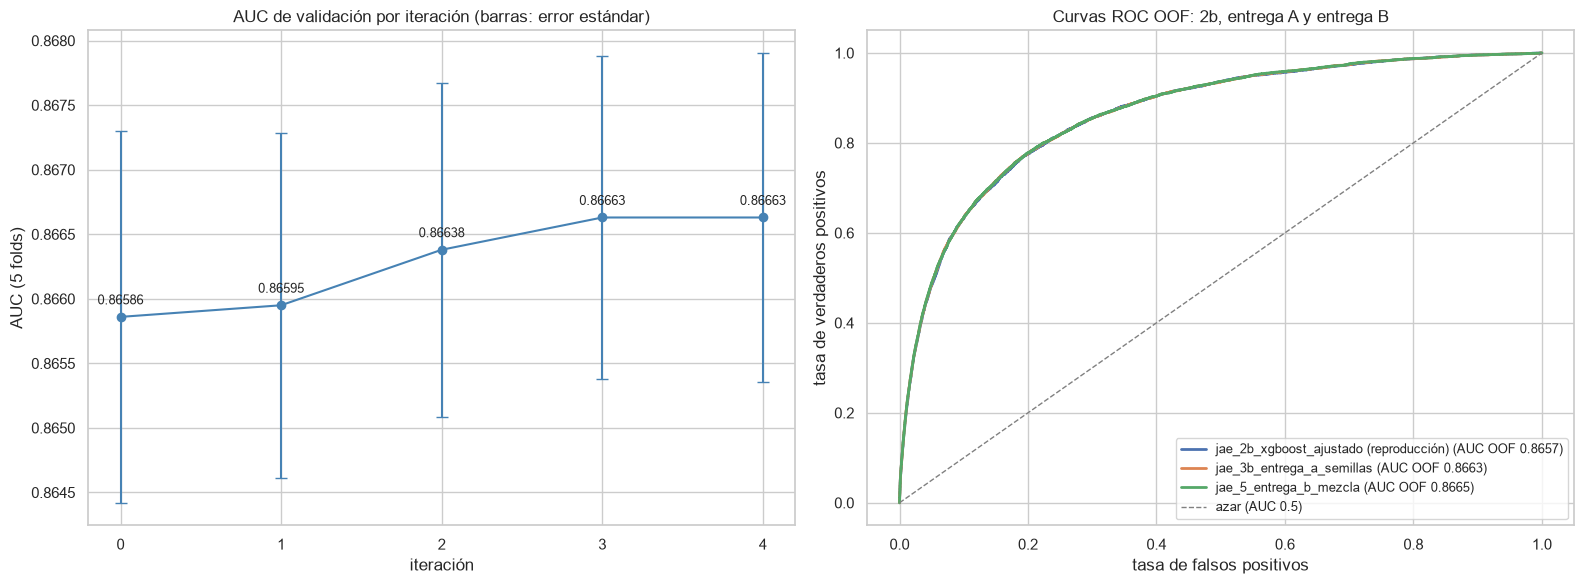

In [10]:
# AUC fold por fold de cada iteración
por_fold = pd.DataFrame(
    {f"{k} · {resultados[k].nombre}": resultados[k].auc_folds for k in resultados},
    index=[f"fold {i}" for i in range(1, 6)],
)
display(por_fold.round(5))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ax = axes[0]
medias = tabla_traza["AUC"]
ax.errorbar(
    medias.index,
    medias,
    yerr=tabla_traza["desv"] / np.sqrt(5),
    marker="o",
    capsize=4,
    color="steelblue",
)
for clave, valor in medias.items():
    ax.annotate(f"{valor:.5f}", (clave, valor), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=9)
ax.set_title("AUC de validación por iteración (barras: error estándar)")
ax.set_xlabel("iteración")
ax.set_ylabel("AUC (5 folds)")
graficar_roc_oof([resultados["0"], resultados["2"], resultados["4"]], y, ax=axes[1])
axes[1].set_title("Curvas ROC OOF: 2b, entrega A y entrega B")
plt.tight_layout()
plt.show()

**Lectura de la traza:**
- **De 2b a la entrega B: +0.00077** (0.86586 → 0.86663), con ventaja en
  los 5 folds. La entrega A queda a medio camino: +0.00052, 4 de 5 folds.
- **Qué aportó cada cambio:**
  - `learning_rate` 0.01: +0.00009 (ruido).
  - Árboles fijos con todo el fold + 5 semillas: +0.00043.
  - Conjunto FE en lugar de JAE: +0.00025.
  - Mezcla JAE + FE: 0.00000 sobre FE, +0.00025 sobre la entrega A.
- **Las mejoras son pequeñas frente a la variabilidad entre folds**
  (≈ 0.003), pero la comparación es pareada: el error estándar de las
  diferencias es de 0.00005 a 0.00017, y por eso se distinguen del ruido.
- Las curvas ROC de 2b, A y B son prácticamente indistinguibles a simple
  vista: se trata de ajustes finos, no de un salto de desempeño.

**Registro en la bitácora del equipo** (`reports/experiments.csv`).

In [11]:
DESCRIPCIONES = {
    "1": (DATASET_JAE, f"XGBoost 2b lr=0.01 + ES (≈ {ARBOLES_JAE} árboles)"),
    "2": (DATASET_JAE, f"XGBoost 2b lr=0.01, {ARBOLES_JAE} árboles, 5 semillas"),
    "3": (DATASET_FE, f"XGBoost 2b lr=0.01, {ARBOLES_FE} árboles, 5 semillas"),
    "4": ("JAE + FE", "mezcla 50/50 de jae_3b y jae_4"),
}
for clave, (features, modelo) in DESCRIPCIONES.items():
    registrar_en_bitacora(
        resultados[clave],
        features=features,
        modelo=modelo,
        notas=(
            f"notebooks/05_mejora_modelos_jae; iteración {clave}; "
            f"AUC OOF {resultados[clave].auc_oof:.5f}"
        ),
    )
read_log().sort_values("cv_auc_mean", ascending=False)[
    ["nombre", "modelo", "cv_auc_mean", "cv_auc_std", "kaggle_score"]
].head(8)

,nombre,modelo,cv_auc_mean,cv_auc_std,kaggle_score
10,jae_4_xgboost_fe_semillas,"XGBoost 2b lr=0.01, 777 árboles, 5 semillas",0.86663,0.00280,NaN
11,jae_5_entrega_b_mezcla,mezcla 50/50 de jae_3b y jae_4,0.86663,0.00285,NaN
9,jae_3b_entrega_a_semillas,"XGBoost 2b lr=0.01, 764 árboles, 5 semillas",0.86638,0.00289,NaN
8,jae_3a_xgboost_lr001,XGBoost 2b lr=0.01 + ES (≈ 764 árboles),0.86595,0.00299,NaN
6,jae_2b_xgboost_ajustado,"XGBoost {'subsample': 0.6, 'reg_lambda': 10.0, 'min_child_weight': 10, 'max_depth': 6, 'gamma': 0.5, 'colsample_bytree': 0.7} + ES",0.86586,0.00322,NaN
5,jae_2a_xgboost_base,XGBoost lr=0.05 depth=4 + ES,0.86489,0.00275,NaN
7,jae_2c_xgboost_pesos,XGBoost 2b + scale_pos_weight=14.0,0.86464,0.00254,NaN
2,baseline_lightgbm,LGBMClassifier,0.86355,0.00242,0.87884


## 7. Entregas
Cada modelo se reentrena con todo `train`, una vez por semilla, y se
promedian las probabilidades sobre `test`:
- **Entrega A:** promedio de las 5 semillas del conjunto JAE.
- **Entrega B:** promedio de la entrega A y de las 5 semillas del conjunto
  FE.

In [12]:
def predecir_semillas(
    crear_modelo: object, X_entrenamiento: pd.DataFrame, X_prueba: pd.DataFrame
) -> np.ndarray:
    """Reentrena el modelo con todo train por cada semilla y promedia en test.

    Args:
        crear_modelo: Función que recibe una semilla y devuelve el modelo sin
            ajustar.
        X_entrenamiento: Variables de todo ``train``.
        X_prueba: Variables de ``test``.

    Returns:
        Probabilidad promedio de las semillas para cada fila de ``test``.
    """
    predicciones = [
        crear_modelo(semilla).fit(X_entrenamiento, y).predict_proba(X_prueba)[:, 1]
        for semilla in SEMILLAS
    ]
    return np.mean(predicciones, axis=0)


def guardar_entrega(probabilidad: np.ndarray, archivo: str) -> pd.DataFrame:
    """Guarda una entrega con el formato de ``sample_submission.csv`` y la verifica.

    Args:
        probabilidad: Probabilidad de morosidad de cada fila de ``test``.
        archivo: Nombre del archivo dentro de ``data/processed/jae/``.

    Returns:
        Entrega guardada.

    Raises:
        AssertionError: Si el formato no coincide con el de la muestra.
    """
    entrega = (
        pd.DataFrame({ID: test_raw[ID].to_numpy(), TARGET: probabilidad})
        .set_index(ID)
        .loc[muestra[ID]]
        .reset_index()
    )
    assert list(entrega.columns) == list(muestra.columns), "Columnas distintas"
    assert len(entrega) == len(muestra), "Número de filas distinto"
    assert (entrega[ID].to_numpy() == muestra[ID].to_numpy()).all(), "Orden de Id distinto"
    assert entrega[TARGET].notna().all(), "Hay probabilidades nulas"
    assert entrega[TARGET].between(0, 1).all(), "Probabilidades fuera de [0, 1]"
    entrega.to_csv(SALIDA / archivo, index=False)
    print(
        f"✅ {(SALIDA / archivo).relative_to(ROOT)}: {len(entrega):,} filas, "
        f"media {probabilidad.mean():.4f}, rango {probabilidad.min():.4f}–"
        f"{probabilidad.max():.4f}"
    )
    return entrega


proba_jae = predecir_semillas(
    lambda semilla: modelo_jae(
        learning_rate=LEARNING_RATE, n_estimators=ARBOLES_JAE, random_state=semilla
    ),
    X_jae,
    X_jae_test,
)
proba_fe = predecir_semillas(
    lambda semilla: clasificador(
        learning_rate=LEARNING_RATE, n_estimators=ARBOLES_FE, random_state=semilla
    ),
    X_fe,
    X_fe_test,
)
entrega_a = guardar_entrega(proba_jae, "submission_a_semillas.csv")
entrega_b = guardar_entrega((proba_jae + proba_fe) / 2, "submission_b_mezcla.csv")

# Comparación con la entrega anterior (2b), si existe
anterior = SALIDA / "submission.csv"
if anterior.exists():
    previa = pd.read_csv(anterior)[TARGET]
    comparacion = pd.DataFrame(
        {
            "Spearman con 2b": [
                entrega_a[TARGET].corr(previa, method="spearman"),
                entrega_b[TARGET].corr(previa, method="spearman"),
            ]
        },
        index=["entrega A", "entrega B"],
    )
    display(comparacion.round(4))
print(f"Tasa de morosidad en train: {y.mean():.4f}")

# Predicciones OOF de las entregas, para futuras mezclas
pd.DataFrame(
    {
        ID: train_raw[ID],
        "oof_2b": resultados["0"].oof,
        "oof_entrega_a": resultados["2"].oof,
        "oof_fe": resultados["3"].oof,
        "oof_entrega_b": resultados["4"].oof,
        TARGET: y,
    }
).to_parquet(SALIDA / "oof_mejora_05.parquet", index=False)

✅ data/processed/jae/submission_a_semillas.csv: 45,000 filas, media 0.0664, rango 0.0029–0.8548
✅ data/processed/jae/submission_b_mezcla.csv: 45,000 filas, media 0.0665, rango 0.0027–0.8577


,Spearman con 2b
entrega A,0.9972
entrega B,0.9968


Tasa de morosidad en train: 0.0668


**Lectura:** las dos entregas tienen 45,000 filas, el orden de `Id` de
`sample_submission.csv`, sin nulos y con probabilidad media (0.0664 y
0.0665) igual a la tasa de morosidad de `train` (0.0668). Su orden coincide
casi por completo con el de la entrega 2b (Spearman 0.997), así que el
puntaje en Kaggle debería moverse poco. Quedan en `data/processed/jae/`,
que no se versiona.

## 8. Conclusiones

1. **Entrega B (mezcla JAE + FE):** AUC de 0.86663 en validación cruzada,
   +0.00077 sobre el XGBoost 2b y con ventaja en los 5 folds. Es la
   recomendada.
2. **Entrega A (JAE, 5 semillas):** 0.86638, +0.00052 sobre 2b en 4 de 5
   folds.
3. **Lo que más ayudó** fue entrenar con todo el fold y un número fijo de
   árboles; el promedio de semillas y `learning_rate=0.01` aportaron poco
   por sí solos.
4. **El conjunto FE supera ligeramente al JAE** con el mismo modelo. Vale la
   pena revisar sus interacciones (`age_x_util`, `late_x_util`,
   `non_re_lines`) para incorporarlas a `engineering_jae`.
5. **Los modelos son muy parecidos entre sí** (Spearman 0.998): mezclar más
   XGBoost similares ya no aportará. Para ganar diversidad hacen falta
   modelos distintos.
6. **Cautela con el *leaderboard*:** las mejoras son del orden de 0.0005 a
   0.0008. La distancia con el equipo que va adelante (0.0002) es menor que
   el ruido del puntaje público, así que la entrega se decide con la
   validación cruzada y no envío por envío.

**Siguientes pasos:**
1. Subir las entregas A y B a Kaggle y registrar su puntaje en la bitácora.
2. Agregar las interacciones de FE a `engineering_jae` y medir si un solo
   conjunto iguala a la mezcla.
3. Buscar diversidad real para la mezcla: CatBoost, o XGBoost con otra
   profundidad y otra función de pérdida.